In [1]:
import pyccl as ccl
import numpy as np
import matplotlib.pyplot as plt
from itertools import pairwise

import sys
sys.path.append('../')
from src import load_config, fisher_matrix, redshift_distributions, names_to_latex

## Load configuration

In [2]:
config = load_config('../configs/config_baryons_bias.yaml')
config_lowbar = load_config('../configs/config_lowbaryons_bias.yaml')

## Setup and compute the Fisher matrix

In [3]:
print(f'Running fisher analysis for {config.name}.')
# Load the cosmology
ccl_cosmo_params = dict(zip(config.cosmology.keys(), config.cosmology.values()))
if 'Omega_m' in ccl_cosmo_params.keys():
    ccl_cosmo_params['Omega_c'] = ccl_cosmo_params['Omega_m'] - ccl_cosmo_params['Omega_b']
    ccl_cosmo_params.pop('Omega_m')
cosmo = ccl.Cosmology(**ccl_cosmo_params,
                      matter_power_spectrum='camb',
                      extra_parameters = {"camb": config.baryons_dict})

# ell binning setup
ell_bins = np.geomspace(config.ell_binning.cosmic_shear.bin_start,
                            config.ell_binning.cosmic_shear.bin_end,
                            config.ell_binning.cosmic_shear.N_bins)
ell_bins = ell_bins[
    (ell_bins >= config.ell_binning.cosmic_shear.ell_min) &
    (ell_bins <= config.ell_binning.cosmic_shear.ell_max)
    ].astype(int)
ell_arr = np.array([(a + b) / 2 for a, b in pairwise(ell_bins)]).astype(int)
Delta_ell = np.array([b - a for a, b in pairwise(ell_bins)])

# Or your own binning here
#ell_arr = np.arange(50, 1000)
#Delta_ell = None

# Define the forecasting setup
sigma_e = config.forecast.e_rms  # e-RMS for shape noise.
N_z_bins = config.redshift_distributions.sources.N_z_bins  # Number of z-bins.
z_arr = np.linspace(config.forecast.z_min, config.forecast.z_max,
                    config.forecast.N_z_values)
nz_arr, zbin_edges = (
    redshift_distributions.get_redshift_distributions(
        z_arr, N_z_bins,
        config.redshift_distributions.sources.z0,
        config.redshift_distributions.sources.a,
        config.redshift_distributions.sources.sigma_z))
# Galaxy number density, if not wanted to be from LSST Y1/Y10
#config['redshift_distributions']['sources']['nbar'] = 5./(4.*np.pi/(41253.0*60.0*60.0))

# Define the fisher matrix setup
cosmo_params = {'name': list(config.cosmology.keys()),
                'fiducial': list(config.cosmology.values()),
                'shift': [config.derivatives.step_size[x] for x in list(config.cosmology.keys())],
                'latex': [names_to_latex(x) for x in config.cosmology.keys()]}
astro_params = {'name': list(config.IA.keys())+list(config.baryons.keys()),
                'fiducial': list(config.IA.values())+list(config.baryons.values()),
                'shift': [config.derivatives.step_size[x] for x in list(config.IA.keys())+list(config.baryons.keys())],
                'latex': [names_to_latex(x) for x in list(config.IA.keys())+list(config.baryons.keys())]}
redshift_params = {'name': [f'dz{i+1}' for i in range(N_z_bins)],
                   'fiducial': [0.] * N_z_bins,
                   'shift': [config.derivatives.step_size.delta_z] * N_z_bins,
                   'latex': [r'$\Delta z_{%i}$' % (i + 1) for i in range(N_z_bins)]}

# Compute the fisher matrix
print(f'Computing fisher matrix.')
fm = fisher_matrix(cosmo=cosmo, z=z_arr, dndz=nz_arr, ell=ell_arr,
                   sigma_e=sigma_e,
                   n_bar=config.redshift_distributions.sources.nbar,
                   fsky=config.forecast.fsky, Delta_ell=Delta_ell,
                   n_points=config.derivatives.stencil_points, cosmo_params=cosmo_params,
                   astro_params=astro_params, redshift_params=redshift_params)
# Add Gaussian photo-z priors
mean_z = np.trapezoid(nz_arr * z_arr, z_arr)
scale_z = config.redshift_distributions.sources.sigma_delta_z*(1+mean_z)
fm.add_prior(redshift_params['name'], scale_z)

Running fisher analysis for baryons.
Computing fisher matrix.


In [4]:
print(f'Running fisher analysis for {config_lowbar.name}.')
# Load the cosmology
ccl_cosmo_params = dict(zip(config_lowbar.cosmology.keys(), config_lowbar.cosmology.values()))
if 'Omega_m' in ccl_cosmo_params.keys():
    ccl_cosmo_params['Omega_c'] = ccl_cosmo_params['Omega_m'] - ccl_cosmo_params['Omega_b']
    ccl_cosmo_params.pop('Omega_m')
cosmo = ccl.Cosmology(**ccl_cosmo_params,
                      matter_power_spectrum='camb',
                      extra_parameters = {"camb": config_lowbar.baryons_dict})

# ell binning setup
ell_bins = np.geomspace(config_lowbar.ell_binning.cosmic_shear.bin_start,
                            config_lowbar.ell_binning.cosmic_shear.bin_end,
                            config_lowbar.ell_binning.cosmic_shear.N_bins)
ell_bins = ell_bins[
    (ell_bins >= config_lowbar.ell_binning.cosmic_shear.ell_min) &
    (ell_bins <= config_lowbar.ell_binning.cosmic_shear.ell_max)
    ].astype(int)
ell_arr = np.array([(a + b) / 2 for a, b in pairwise(ell_bins)]).astype(int)
Delta_ell = np.array([b - a for a, b in pairwise(ell_bins)])

# Or your own binning here
#ell_arr = np.arange(50, 1000)
#Delta_ell = None

# Define the forecasting setup
sigma_e = config_lowbar.forecast.e_rms  # e-RMS for shape noise.
N_z_bins = config_lowbar.redshift_distributions.sources.N_z_bins  # Number of z-bins.
z_arr = np.linspace(config_lowbar.forecast.z_min, config_lowbar.forecast.z_max,
                    config_lowbar.forecast.N_z_values)
nz_arr, zbin_edges = (
    redshift_distributions.get_redshift_distributions(
        z_arr, N_z_bins,
        config_lowbar.redshift_distributions.sources.z0,
        config_lowbar.redshift_distributions.sources.a,
        config_lowbar.redshift_distributions.sources.sigma_z))
# Galaxy number density, if not wanted to be from LSST Y1/Y10
#config_lowbar['redshift_distributions']['sources']['nbar'] = 5./(4.*np.pi/(41253.0*60.0*60.0))

# Define the fisher matrix setup
cosmo_params = {'name': list(config_lowbar.cosmology.keys()),
                'fiducial': list(config_lowbar.cosmology.values()),
                'shift': [config_lowbar.derivatives.step_size[x] for x in list(config_lowbar.cosmology.keys())],
                'latex': [names_to_latex(x) for x in config_lowbar.cosmology.keys()]}
astro_params = {'name': list(config_lowbar.IA.keys())+list(config_lowbar.baryons.keys()),
                'fiducial': list(config_lowbar.IA.values())+list(config_lowbar.baryons.values()),
                'shift': [config_lowbar.derivatives.step_size[x] for x in list(config_lowbar.IA.keys())+list(config_lowbar.baryons.keys())],
                'latex': [names_to_latex(x) for x in list(config_lowbar.IA.keys())+list(config_lowbar.baryons.keys())]}
redshift_params = {'name': [f'dz{i+1}' for i in range(N_z_bins)],
                   'fiducial': [0.] * N_z_bins,
                   'shift': [config_lowbar.derivatives.step_size.delta_z] * N_z_bins,
                   'latex': [r'$\Delta z_{%i}$' % (i + 1) for i in range(N_z_bins)]}

# Compute the fisher matrix
print(f'Computing fisher matrix.')
fm_lowb = fisher_matrix(cosmo=cosmo, z=z_arr, dndz=nz_arr, ell=ell_arr,
                   sigma_e=sigma_e,
                   n_bar=config_lowbar.redshift_distributions.sources.nbar,
                   fsky=config_lowbar.forecast.fsky, Delta_ell=Delta_ell,
                   n_points=config_lowbar.derivatives.stencil_points, cosmo_params=cosmo_params,
                   astro_params=astro_params, redshift_params=redshift_params)
# Add Gaussian photo-z priors
mean_z = np.trapezoid(nz_arr * z_arr, z_arr)
scale_z = config_lowbar.redshift_distributions.sources.sigma_delta_z*(1+mean_z)
fm_lowb.add_prior(redshift_params['name'], scale_z)

Running fisher analysis for low_baryons.
Computing fisher matrix.


In [5]:
fmS8 = fm.transform_A_s_to_S8()
fmS8_marginalised = fisher_matrix(
    cosmo_params={
        'name': ['Omega_m', 'S8'],
        'fiducial': [fmS8.fiducial_parameters[0], fmS8.fiducial_parameters[3]],
        'latex': [names_to_latex(x) for x in ['Omega_m', 'S8']]
    },
    astro_params=fm.astro_params,
    fisher_from_input=np.linalg.inv(fmS8.marginalised_covariance(['Omega_m', 'S8', 'logT_AGN'])))

In [6]:
fm_lowbS8 = fm_lowb.transform_A_s_to_S8()
fm_lowbS8_marginalised = fisher_matrix(
    cosmo_params={
        'name': ['Omega_m', 'S8'],
        'fiducial': [fm_lowbS8.fiducial_parameters[0], fm_lowbS8.fiducial_parameters[3]],
        'latex': [names_to_latex(x) for x in ['Omega_m', 'S8']]
    },
    astro_params=fm_lowb.astro_params,
    fisher_from_input=np.linalg.inv(fm_lowbS8.marginalised_covariance(['Omega_m', 'S8', 'logT_AGN'])))

## Compute the bias assuming a $\delta \log T_\mathrm{AGN}$
Compute the expected bias
$$
(\delta\theta) = (F_{\theta\theta})^{-1}\,\left(F_{\theta,\log T_\mathrm{AGN}}\right)^\mathrm{T}\,\delta \log T_\mathrm{AGN}
$$
where the fisher matrix $F_{\theta\theta}$ is the matrix by fixing the systematics parameters and $F_{\theta,\log T_\mathrm{AGN}}$ is a vector with the elements in the fisher matrix corresponding to $\theta$ and $\log T_\mathrm{AGN}$.

In [7]:
f_theta_logT_AGN = np.zeros(len(fmS8_marginalised.parameters)-1)
i=0
for ip, p in enumerate(fmS8_marginalised.parameters):
    if p=='logT_AGN':
        continue
    f_theta_logT_AGN[i] = fmS8_marginalised[p, 'logT_AGN'][0,1]
    i += 1
f_fixed = fmS8_marginalised.fix_parameters(['logT_AGN'])

delta_psi = fmS8_marginalised.astro_params['fiducial'][2]-fm_lowbS8_marginalised.astro_params['fiducial'][2]
delta_theta = f_fixed.covariance.dot(f_theta_logT_AGN) * delta_psi

for ip, p in enumerate(fmS8_marginalised.parameters):
    if p=='logT_AGN': continue
    print(f'{p} bias: {delta_theta[ip]}')

Omega_m bias: -0.011074303192833744
S8 bias: -0.03065445316926548


### Plot the bias:

In [8]:
biased_centers = fmS8_marginalised.fiducial_parameters[:-1]+delta_theta

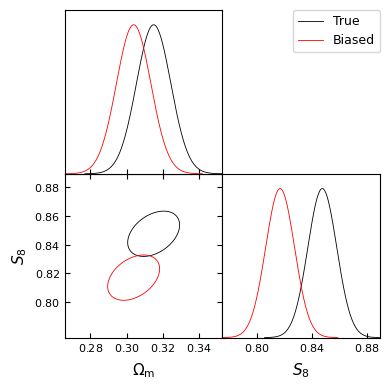

In [9]:
from getdist import plots, MCSamples
from getdist.gaussian_mixtures import GaussianND
f_true = GaussianND(fmS8_marginalised.fiducial_parameters[:-1].astype(float), fmS8_marginalised.marginalised_covariance(fmS8_marginalised.parameters[:-1]),
                    labels=[x.strip('$') for x in fmS8_marginalised.latex_parameters[:-1]],
                    names=fmS8_marginalised.parameters[:-1])
f_biased = GaussianND(biased_centers.astype(float), fmS8_marginalised.marginalised_covariance(fmS8_marginalised.parameters[:-1]),
                    labels=[x.strip('$') for x in fmS8_marginalised.latex_parameters[:-1]],
                    names=fmS8_marginalised.parameters[:-1])


# Triangle plot
g = plots.get_subplot_plotter()
#g.settings.legend_fontsize = 24
#g.settings.axes_labelsize = 24
#g.settings.axes_fontsize = 20
g.settings.num_plot_contours = 1
g.triangle_plot([f_true, f_biased], legend_labels=['True', 'Biased'], filled=False)

### Sensitivity

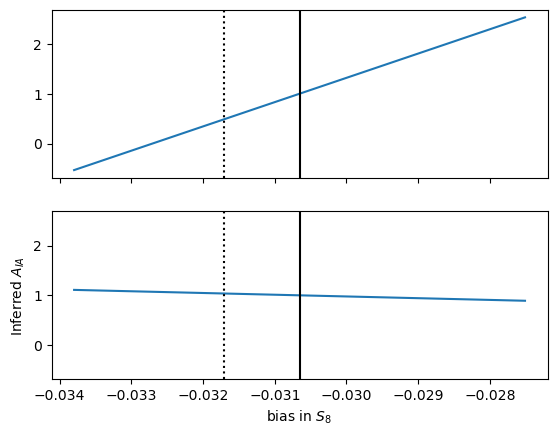

In [10]:
sigma_theta = np.diag(fmS8_marginalised.covariance)**0.5

Om_biases = np.linspace(delta_theta[0]-0.3*sigma_theta[0], delta_theta[0]+0.3*sigma_theta[0], 100)
S8_biases = np.linspace(delta_theta[1]-0.3*sigma_theta[1], delta_theta[1]+0.3*sigma_theta[1], 100)

deltapsi_true = np.zeros((2, 100))

fig, ax = plt.subplots(2, sharex=True, sharey=True)
for i in range(100):
    deltapsi_true[:,i] = (f_fixed.fisher_matrix @ np.array([delta_theta[0], S8_biases[i]])) / f_theta_logT_AGN
ax[0].plot(S8_biases, deltapsi_true[0])
ax[1].plot(S8_biases, deltapsi_true[1])
for a in ax:
    a.axvline(delta_theta[1], color='k')
    a.axvline(delta_theta[1]-0.1*sigma_theta[1], color='k', ls=':')
    #a.set_ylim([-0.2,0.2])
ax[-1].set_xlabel('bias in $S_8$')
ax[1].set_ylabel('Inferred $A_{IA}$')
plt.show()

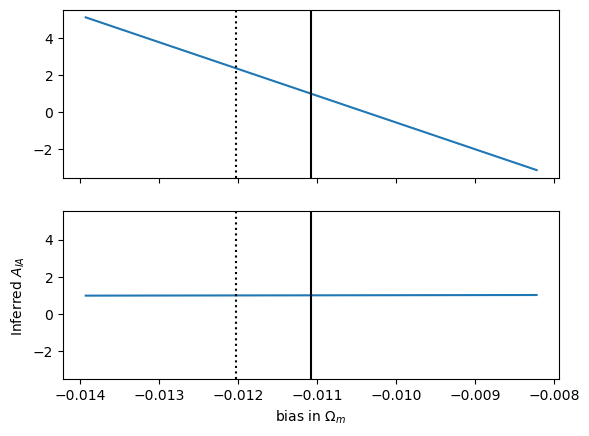

In [11]:
deltapsi_true = np.zeros((2, 100))

fig, ax = plt.subplots(2, sharex=True, sharey=True)
for i in range(100):
    deltapsi_true[:,i] = (f_fixed.fisher_matrix @ np.array([Om_biases[i], delta_theta[1]])) / f_theta_logT_AGN
ax[0].plot(Om_biases, deltapsi_true[0])
ax[1].plot(Om_biases, deltapsi_true[1])
for a in ax:
    a.axvline(delta_theta[0], color='k')
    a.axvline(delta_theta[0]-0.1*sigma_theta[0], color='k', ls=':')
    #a.set_ylim([-0.1,0.1])
ax[-1].set_xlabel(r'bias in $\Omega_m$')
ax[1].set_ylabel('Inferred $A_{IA}$')
plt.show()